<table>
    <tr>
        <td><img src="https://raw.githubusercontent.com/Fabian830348/Bases_Datos/refs/heads/master/logo_ECI.png" width="300"/></td>
        <td>&nbsp;</td>
        <td>
            <h1 style="font-size:200%;color:blue;text-align:center"><FONT COLOR="blue">Caso de Estudio <p> Final</FONT></h1></td>
        <td>
            <tp><p style="font-size:99%;text-align:center">Redes Neuronales</p></tp>
            <tp><p style="font-size:115%;text-align:center">Pregrado MACC 2026-2</p></tp>
            <tp><p style="font-size:115%;text-align:center">Prof. Fabián Sánchez</p></tp>
        </td>
    </tr>
</table>

# <FONT SIZE=5 COLOR="purple"> Punto 3. Modelos de Generación Sintética de Datos: VAE y GAN </FONT>

**Integrantes:**

- Nombre 1
- Nombre 2
- Nombre 3

# <FONT SIZE=5 COLOR="purple"> Contexto del problema </FONT>

<FONT SIZE=4 COLOR="green"> **Conjunto de datos: Pokémon Images Dataset** </FONT>

Se trabaja con el conjunto de datos [*Pokemon Images Dataset*](https://www.kaggle.com/datasets/kvpratama/pokemon-images-dataset) de Kaggle (autor: *kvpratama*). Contiene **819 imágenes** de Pokémon (sprites oficiales de las generaciones 1 a 7). Cada imagen es de **256 × 256 píxeles**, en formato PNG con canal de transparencia (RGBA), con un único Pokémon centrado sobre un fondo vacío.

| Característica | Valor |
|---|---|
| Número de imágenes | 819 |
| Resolución original | 256 × 256 |
| Canales | RGBA (PNG) / RGB (JPG) |
| Etiquetas | No tiene (aprendizaje no supervisado) |

<FONT SIZE=4 COLOR="green"> **Problema** </FONT>

Un estudio de diseño de videojuegos quiere apoyar a sus ilustradores con una herramienta que **genere bocetos de criaturas nuevas** con el estilo visual de los Pokémon: paleta de colores, siluetas, proporción de figura y fondo. Como cada imagen tiene $64 \times 64 \times 3 = 12.288$ variables (píxeles), el problema es **aprender la distribución conjunta $p(x)$ de las imágenes** y muestrear de ella.

Para esto se comparan dos familias de modelos generativos profundos:

1. **Autoencoder Variacional (VAE):** aprende un espacio latente continuo y regularizado del que se decodifican imágenes nuevas.
2. **Red Generativa Antagónica (GAN, arquitectura DCGAN):** un generador y un discriminador compiten; el generador aprende a producir imágenes que el discriminador no distingue de las reales.

<FONT SIZE=4 COLOR="green"> **Objetivos** </FONT>

- Comparar gráficamente las distribuciones de los datos originales y sintéticos.
- Analizar si los datos generados conservan relaciones relevantes entre variables (canales de color, características de la imagen, estructura espacial).
- Explicar las diferencias entre los resultados obtenidos con el VAE y la GAN.
- Guardar los modelos entrenados para usarlos en la aplicación *Gradio* (Módulo 3).

> **Recomendación:** ejecutar en Google Colab con GPU (*Entorno de ejecución → Cambiar tipo de entorno → GPU T4*). Con GPU el entrenamiento completo tarda unos 10 a 15 minutos. En CPU funciona, pero conviene bajar el número de épocas.

# <FONT SIZE=5 COLOR="purple"> 1. Librerías y configuración </FONT>

In [13]:
import os, glob, json, zipfile, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from scipy import stats, linalg
from sklearn.decomposition import PCA

import tensorflow as tf
import keras
from keras import layers

warnings.filterwarnings("ignore")
print("TensorFlow:", tf.__version__, "| Keras:", keras.__version__)
print("GPU disponible:", tf.config.list_physical_devices("GPU"))

SEED = 42
keras.utils.set_random_seed(SEED)

# ---------------- Configuración general ----------------
IMG_SIZE    = 64      # las imágenes se reducen a 64x64 para entrenar rápido
CHANNELS    = 3
BATCH_SIZE  = 64
LATENT_VAE  = 128     # dimensión del espacio latente del VAE
LATENT_GAN  = 128     # dimensión del ruido de entrada de la GAN
EPOCHS_VAE  = 100
EPOCHS_GAN  = 300     # las GAN necesitan más épocas para estabilizarse
OUT_DIR     = "modelos_generativos"   # aquí se guardan modelos y resultados
os.makedirs(OUT_DIR, exist_ok=True)

# ---------------- Estilo de gráficas ----------------
COL_REAL, COL_VAE, COL_GAN = "#2a78d6", "#eb6834", "#1baf7a"
COLORES = {"Real": COL_REAL, "VAE": COL_VAE, "GAN": COL_GAN}
plt.rcParams.update({
    "figure.dpi": 100, "axes.titleweight": "bold", "axes.titlesize": 12,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "font.size": 10,
})

TensorFlow: 2.21.0 | Keras: 3.13.2
GPU disponible: []


# <FONT SIZE=5 COLOR="purple"> 2. Carga de los datos </FONT>

Se descarga el dataset con `kagglehub`. Si ya lo tiene descargado en su equipo, escriba la ruta en `DATA_DIR` y no se descargará de nuevo.

El dataset trae las mismas imágenes en dos versiones (`pokemon/` en PNG y `pokemon_jpg/` en JPG). Se usan las **PNG** y la transparencia se rellena con **fondo blanco**, para que todas las imágenes tengan el mismo fondo.

In [14]:
DATA_DIR = None   # Ej: r"C:\Users\usuario\Downloads\pokemon-images-dataset"

if DATA_DIR is None:
    import kagglehub
    DATA_DIR = kagglehub.dataset_download("kvpratama/pokemon-images-dataset")
print("Carpeta de datos:", DATA_DIR)

def buscar_imagenes(carpeta):
    """Devuelve una ruta por Pokémon: prefiere PNG y evita duplicados PNG/JPG."""
    pngs = glob.glob(os.path.join(carpeta, "**", "*.png"), recursive=True)
    jpgs = glob.glob(os.path.join(carpeta, "**", "*.jpg"), recursive=True)
    rutas = {}
    for r in sorted(pngs) + sorted(jpgs):
        nombre = os.path.splitext(os.path.basename(r))[0]
        rutas.setdefault(nombre, r)          # si ya hay PNG, se ignora el JPG
    return [rutas[k] for k in sorted(rutas)]

def cargar_imagen(ruta, size=IMG_SIZE):
    img = Image.open(ruta)
    if img.mode in ("RGBA", "LA", "P"):
        img = img.convert("RGBA")
        fondo = Image.new("RGBA", img.size, (255, 255, 255, 255))
        img = Image.alpha_composite(fondo, img)
    img = img.convert("RGB").resize((size, size), Image.LANCZOS)
    return np.asarray(img, dtype=np.float32) / 255.0

rutas = buscar_imagenes(DATA_DIR)
X = np.stack([cargar_imagen(r) for r in rutas])          # valores en [0, 1]
nombres = [os.path.splitext(os.path.basename(r))[0] for r in rutas]

print(f"Imágenes cargadas: {X.shape[0]}")
print(f"Forma del tensor:  {X.shape}  (n, alto, ancho, canales)")
print(f"Rango de valores:  [{X.min():.2f}, {X.max():.2f}]")

Using Colab cache for faster access to the 'pokemon-images-dataset' dataset.
Carpeta de datos: /kaggle/input/pokemon-images-dataset
Imágenes cargadas: 819
Forma del tensor:  (819, 64, 64, 3)  (n, alto, ancho, canales)
Rango de valores:  [0.00, 1.00]


# <FONT SIZE=5 COLOR="purple"> 3. Análisis exploratorio </FONT>

<FONT SIZE=4 COLOR="green"> **3.1 Muestra de imágenes** </FONT>

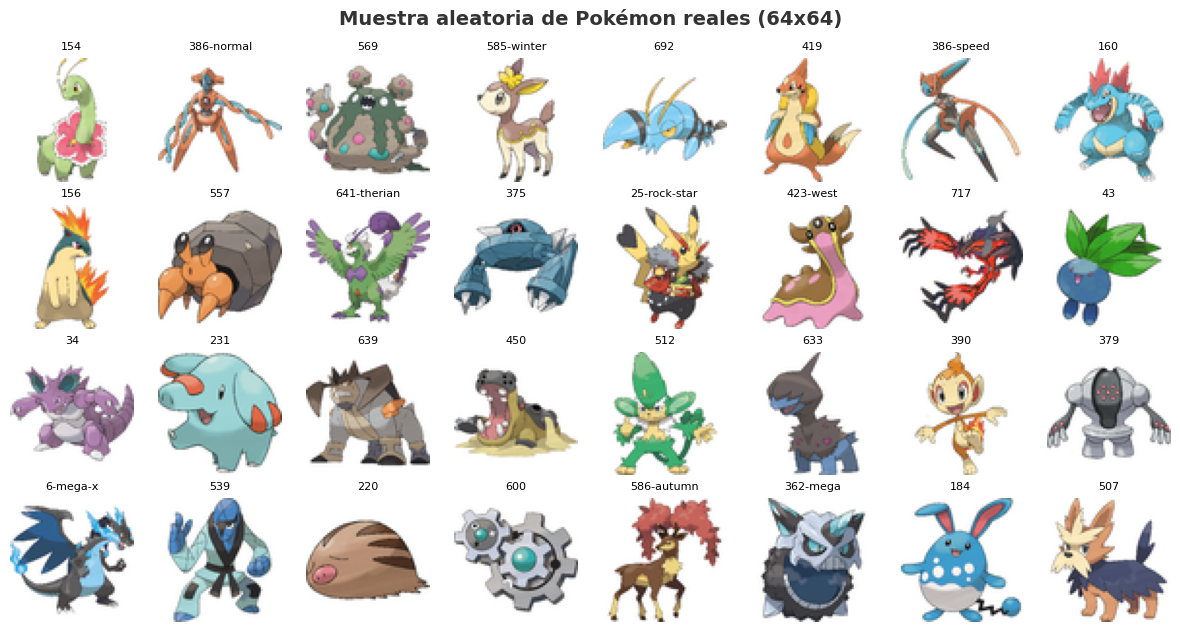

In [15]:
def mostrar_grilla(imgs, titulo, filas=4, cols=8, titulos=None, figsize=None):
    imgs = np.clip(imgs, 0, 1)
    fig, axes = plt.subplots(filas, cols, figsize=figsize or (cols * 1.5, filas * 1.6))
    for i, ax in enumerate(np.array(axes).ravel()):
        ax.axis("off")
        if i < len(imgs):
            ax.imshow(imgs[i])
            if titulos is not None:
                ax.set_title(titulos[i], fontsize=8, fontweight="normal")
    fig.suptitle(titulo, fontsize=14, fontweight="bold", color="#333")
    plt.tight_layout()
    plt.show()

rng = np.random.default_rng(SEED)
idx = rng.choice(len(X), 32, replace=False)
mostrar_grilla(X[idx], "Muestra aleatoria de Pokémon reales (64x64)",
               titulos=[nombres[i] for i in idx])

<FONT SIZE=4 COLOR="green"> **3.2 Características por imagen** </FONT>

Cada imagen tiene 12.288 píxeles, así que comparar píxel a píxel es poco informativo. Por eso se resume cada imagen con **características interpretables**. Estas mismas características se usarán después para comparar las imágenes reales con las sintéticas.

| Característica | Qué mide |
|---|---|
| `brillo` | Intensidad media en escala de grises |
| `contraste` | Desviación estándar de la escala de grises |
| `media_R`, `media_G`, `media_B` | Color promedio de la imagen por canal |
| `saturacion` | Saturación media (HSV) de los píxeles del Pokémon |
| `colorido` | Índice de *colorfulness* de Hasler–Süsstrunk |
| `frac_fondo` | Proporción de píxeles casi blancos (fondo): tamaño de la silueta |
| `nitidez` | Magnitud media de bordes (Sobel): qué tan definidos son los contornos |

In [16]:
def caracteristicas(imgs, lote=256):
    """Calcula 9 características interpretables por imagen (imgs en [0,1])."""
    filas = []
    for i in range(0, len(imgs), lote):
        b = tf.convert_to_tensor(np.clip(imgs[i:i + lote], 0, 1), tf.float32)
        gris = tf.image.rgb_to_grayscale(b)[..., 0]
        hsv = tf.image.rgb_to_hsv(b)
        fondo = tf.reduce_all(b > 0.9, axis=-1)
        objeto = tf.cast(~fondo, tf.float32)
        sat = tf.reduce_sum(hsv[..., 1] * objeto, [1, 2]) / (tf.reduce_sum(objeto, [1, 2]) + 1e-6)
        R, G, B = b[..., 0], b[..., 1], b[..., 2]
        rg, yb = R - G, 0.5 * (R + G) - B
        colorido = (tf.sqrt(tf.math.reduce_std(rg, [1, 2])**2 + tf.math.reduce_std(yb, [1, 2])**2)
                    + 0.3 * tf.sqrt(tf.reduce_mean(rg, [1, 2])**2 + tf.reduce_mean(yb, [1, 2])**2))
        sob = tf.image.sobel_edges(gris[..., None])
        nitidez = tf.reduce_mean(tf.sqrt(tf.reduce_sum(sob**2, -1) + 1e-12), [1, 2, 3])
        filas.append(np.stack([
            tf.reduce_mean(gris, [1, 2]), tf.math.reduce_std(gris, [1, 2]),
            tf.reduce_mean(R, [1, 2]), tf.reduce_mean(G, [1, 2]), tf.reduce_mean(B, [1, 2]),
            sat, colorido, tf.reduce_mean(tf.cast(fondo, tf.float32), [1, 2]), nitidez,
        ], axis=1))
    cols = ["brillo", "contraste", "media_R", "media_G", "media_B",
            "saturacion", "colorido", "frac_fondo", "nitidez"]
    return pd.DataFrame(np.concatenate(filas), columns=cols)

feat_real = caracteristicas(X)
feat_real.describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
brillo,819.0,0.828,0.064,0.584,0.792,0.834,0.875,0.968
contraste,819.0,0.223,0.051,0.091,0.186,0.223,0.258,0.379
media_R,819.0,0.839,0.070,0.558,0.800,0.847,0.890,0.976
media_G,819.0,0.826,0.068,0.589,0.786,0.833,0.877,0.969
media_B,819.0,0.813,0.073,0.587,0.769,0.818,0.863,0.980
saturacion,819.0,0.270,0.116,0.009,0.186,0.266,0.350,0.678
colorido,819.0,0.142,0.062,0.013,0.096,0.139,0.184,0.327
frac_fondo,819.0,0.587,0.112,0.219,0.517,0.598,0.664,0.896
nitidez,819.0,0.401,0.100,0.143,0.329,0.397,0.465,0.837


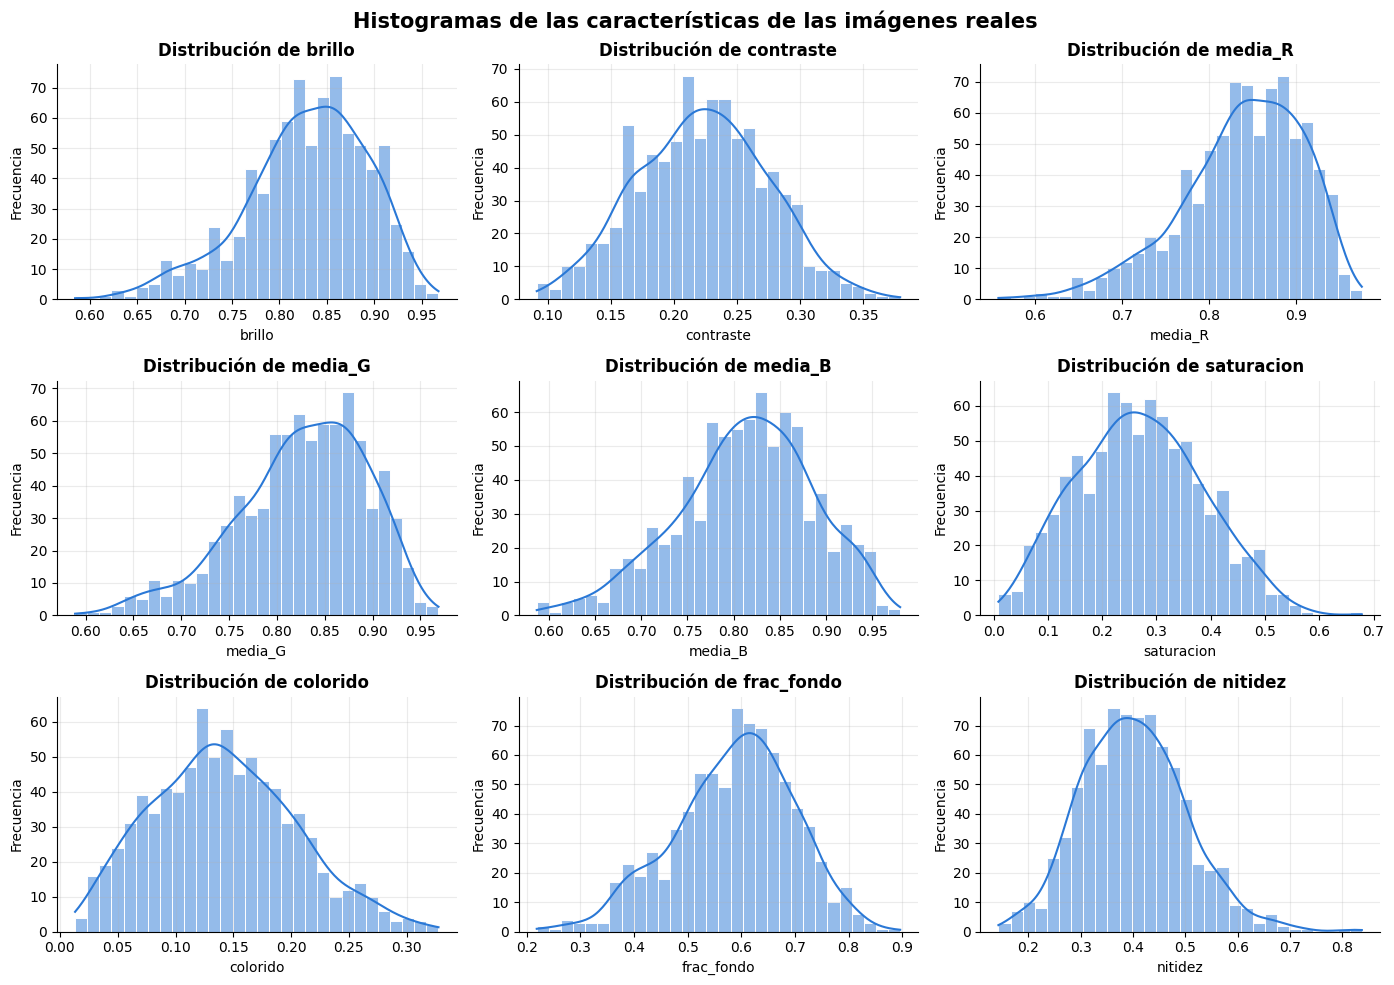

In [17]:
fig, axes = plt.subplots(3, 3, figsize=(14, 10))
for ax, col in zip(axes.ravel(), feat_real.columns):
    sns.histplot(feat_real[col], bins=30, kde=True, color=COL_REAL, ax=ax, edgecolor="white")
    ax.set_title(f"Distribución de {col}")
    ax.set_xlabel(col); ax.set_ylabel("Frecuencia")
fig.suptitle("Histogramas de las características de las imágenes reales", fontsize=15, fontweight="bold")
plt.tight_layout(); plt.show()

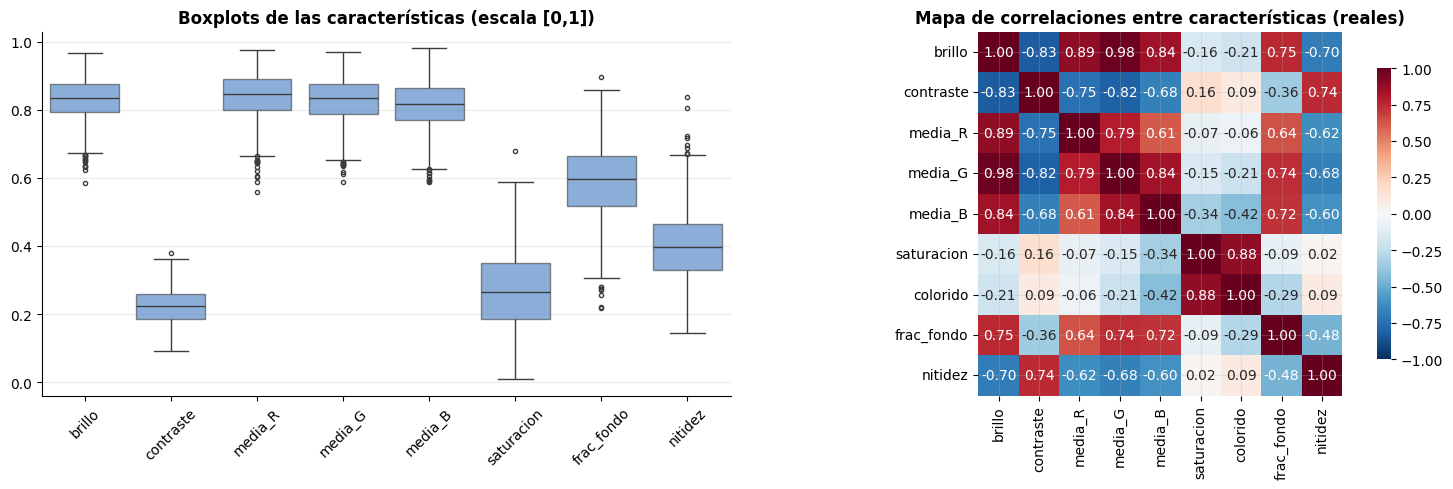

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.boxplot(data=feat_real.drop(columns=["colorido"]), ax=axes[0], color=COL_REAL,
            boxprops=dict(alpha=.6), flierprops=dict(markersize=3))
axes[0].set_title("Boxplots de las características (escala [0,1])")
axes[0].tick_params(axis="x", rotation=45)

sns.heatmap(feat_real.corr(), annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1,
            square=True, ax=axes[1], cbar_kws={"shrink": .8})
axes[1].set_title("Mapa de correlaciones entre características (reales)")
plt.tight_layout(); plt.show()

<FONT SIZE=4 COLOR="green"> **3.3 Distribución de color por canal e imagen promedio** </FONT>

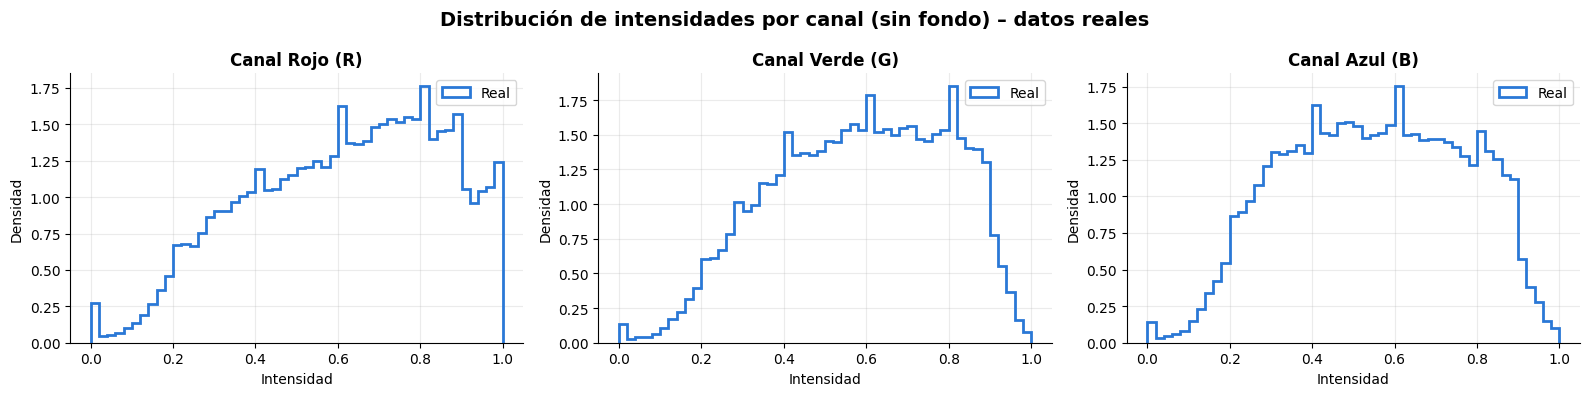

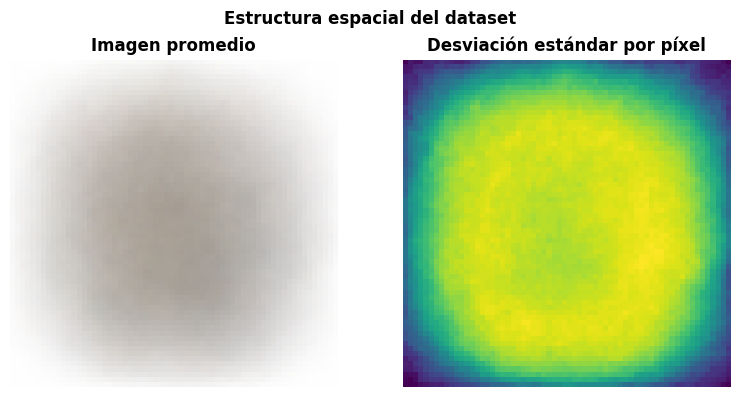

In [19]:
def histograma_canales(imgs_dict, titulo, solo_objeto=True):
    fig, axes = plt.subplots(1, 3, figsize=(16, 4))
    for c, (ax, canal) in enumerate(zip(axes, ["Rojo (R)", "Verde (G)", "Azul (B)"])):
        for nombre, imgs in imgs_dict.items():
            imgs = np.clip(imgs, 0, 1)
            vals = imgs[..., c]
            if solo_objeto:   # se excluye el fondo blanco para ver el color del Pokémon
                vals = vals[~np.all(imgs > 0.9, axis=-1)]
            ax.hist(vals.ravel(), bins=50, density=True, histtype="step", linewidth=2,
                    color=COLORES[nombre], label=nombre)
        ax.set_title(f"Canal {canal}"); ax.set_xlabel("Intensidad"); ax.set_ylabel("Densidad")
        ax.legend()
    fig.suptitle(titulo, fontsize=14, fontweight="bold")
    plt.tight_layout(); plt.show()

histograma_canales({"Real": X}, "Distribución de intensidades por canal (sin fondo) – datos reales")

fig, axes = plt.subplots(1, 2, figsize=(8, 4))
axes[0].imshow(X.mean(0)); axes[0].set_title("Imagen promedio")
axes[1].imshow(X.std(0).mean(-1), cmap="viridis"); axes[1].set_title("Desviación estándar por píxel")
for ax in axes: ax.axis("off")
plt.suptitle("Estructura espacial del dataset", fontweight="bold"); plt.tight_layout(); plt.show()

**Observaciones del análisis exploratorio:**

- Todas las imágenes tienen fondo blanco y un único Pokémon centrado. Por eso la **imagen promedio** es una mancha borrosa en el centro y la variabilidad (desviación estándar) se concentra ahí.
- Una fracción grande de cada imagen es fondo (`frac_fondo`). Un buen modelo generativo debe reproducir **siluetas sobre fondo blanco**, no solo colores.
- Los canales R, G y B están **muy correlacionados** entre sí (y con el brillo). Un buen generador debe conservar esa relación; si no, aparecen colores irreales.
- Con solo ~819 imágenes el dataset es **pequeño** para modelos generativos. Se usa *data augmentation* (volteo horizontal) para ambos modelos y *DiffAugment* para la GAN.

# <FONT SIZE=5 COLOR="purple"> 4. Preparación de los datos </FONT>

- **VAE:** imágenes en $[0,1]$ (salida *sigmoid*). Se separa un 10 % para **validación** y así analizar las curvas de entrenamiento y validación.
- **GAN:** imágenes en $[-1,1]$ (salida *tanh*). Usa todas las imágenes, porque en una GAN la pérdida de validación no mide la calidad de lo generado.
- En ambos casos se aplica volteo horizontal aleatorio como *data augmentation*.

In [20]:
perm = np.random.default_rng(SEED).permutation(len(X))
n_val = int(0.1 * len(X))
X_val, X_train = X[perm[:n_val]], X[perm[n_val:]]
print(f"Entrenamiento VAE: {len(X_train)} | Validación VAE: {len(X_val)} | GAN: {len(X)}")

def flip(x):
    return tf.image.random_flip_left_right(x)

ds_vae_train = (tf.data.Dataset.from_tensor_slices(X_train).shuffle(1000, seed=SEED)
                .map(flip, num_parallel_calls=tf.data.AUTOTUNE)
                .batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE))
ds_vae_val = tf.data.Dataset.from_tensor_slices(X_val).batch(BATCH_SIZE)

ds_gan = (tf.data.Dataset.from_tensor_slices(X * 2.0 - 1.0).shuffle(1000, seed=SEED)
          .map(flip, num_parallel_calls=tf.data.AUTOTUNE)
          .batch(BATCH_SIZE, drop_remainder=True).prefetch(tf.data.AUTOTUNE))

Entrenamiento VAE: 738 | Validación VAE: 81 | GAN: 819


# <FONT SIZE=5 COLOR="purple"> 5. Autoencoder Variacional (VAE) </FONT>

El VAE tiene un **codificador** $q_\phi(z|x)$ que transforma cada imagen en una distribución normal $\mathcal{N}(\mu, \sigma^2)$ en el espacio latente, y un **decodificador** $p_\theta(x|z)$ que reconstruye la imagen a partir de una muestra $z$. Para que se pueda derivar a través del muestreo se usa el **truco de reparametrización**:

$$ z = \mu + \sigma \odot \varepsilon, \qquad \varepsilon \sim \mathcal{N}(0, I) $$

La función de pérdida (ELBO negativa) combina dos términos:

$$ \mathcal{L} = \underbrace{\sum_{píxeles} \text{BCE}(x, \hat{x})}_{\text{reconstrucción}} \; + \; \beta \cdot \underbrace{\left(-\tfrac{1}{2}\sum_j \left(1 + \log\sigma_j^2 - \mu_j^2 - \sigma_j^2\right)\right)}_{\text{KL}(q(z|x)\,\|\,\mathcal{N}(0,I))} $$

El término KL obliga a que el espacio latente se parezca a una normal estándar. Gracias a eso se pueden **generar imágenes nuevas** muestreando $z \sim \mathcal{N}(0, I)$ y pasándolo por el decodificador.

In [21]:
class Muestreo(layers.Layer):
    """Truco de reparametrización: z = mu + sigma * epsilon."""
    def call(self, inputs):
        z_mean, z_log_var = inputs
        eps = tf.random.normal(tf.shape(z_mean))
        return z_mean + tf.exp(0.5 * z_log_var) * eps

# ---------------- Codificador ----------------
enc_in = keras.Input(shape=(IMG_SIZE, IMG_SIZE, CHANNELS), name="imagen")
x = enc_in
for f in [32, 64, 128, 256]:                       # 64 -> 32 -> 16 -> 8 -> 4
    x = layers.Conv2D(f, 4, strides=2, padding="same")(x)
    x = layers.BatchNormalization()(x)
    x = layers.LeakyReLU(0.2)(x)
x = layers.Flatten()(x)
x = layers.Dense(512, activation="relu")(x)
z_mean = layers.Dense(LATENT_VAE, name="z_mean")(x)
z_log_var = layers.Dense(LATENT_VAE, name="z_log_var")(x)
z = Muestreo(name="z")([z_mean, z_log_var])
encoder = keras.Model(enc_in, [z_mean, z_log_var, z], name="encoder")

# ---------------- Decodificador ----------------
dec_in = keras.Input(shape=(LATENT_VAE,), name="z")
x = layers.Dense(4 * 4 * 256, activation="relu")(dec_in)
x = layers.Reshape((4, 4, 256))(x)
for f in [256, 128, 64, 32]:                       # 4 -> 8 -> 16 -> 32 -> 64
    x = layers.Conv2DTranspose(f, 4, strides=2, padding="same")(x)
    x = layers.BatchNormalization()(x)
    x = layers.LeakyReLU(0.2)(x)
dec_out = layers.Conv2D(CHANNELS, 3, padding="same", activation="sigmoid", name="imagen_rec")(x)
decoder = keras.Model(dec_in, dec_out, name="decoder")

encoder.summary()
decoder.summary()

Model: "encoder"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ imagen (InputLayer) │ (None, 64, 64, 3) │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_4 (Conv2D)   │ (None, 32, 32,    │      1,568 │ imagen[0][0]      │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 32, 32,    │        128 │ conv2d_4[0][0]    │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ leaky_re_lu_8       │ (None, 32, 32,    │          0 │ batch_normalizat… │
│ (LeakyReLU)         │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_5 (Conv2D)   │ (None, 16, 16,    │     32,832 │ leaky_re_lu_8[0]… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 16, 16,    │        256 │ conv2d_5[0][0]    │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ leaky_re_lu_9       │ (None, 16, 16,    │          0 │ batch_normalizat… │
│ (LeakyReLU)         │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_6 (Conv2D)   │ (None, 8, 8, 128) │    131,200 │ leaky_re_lu_9[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 8, 8, 128) │        512 │ conv2d_6[0][0]    │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ leaky_re_lu_10      │ (None, 8, 8, 128) │          0 │ batch_normalizat… │
│ (LeakyReLU)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_7 (Conv2D)   │ (None, 4, 4, 256) │    524,544 │ leaky_re_lu_10[0… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 4, 4, 256) │      1,024 │ conv2d_7[0][0]    │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ leaky_re_lu_11      │ (None, 4, 4, 256) │          0 │ batch_normalizat… │
│ (LeakyReLU)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten_1 (Flatten) │ (None, 4096)      │          0 │ leaky_re_lu_11[0… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_2 (Dense)     │ (None, 512)       │  2,097,664 │ flatten_1[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ z_mean (Dense)      │ (None, 128)       │     65,664 │ dense_2[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ z_log_var (Dense)   │ (None, 128)       │     65,664 │ dense_2[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ z (Muestreo)        │ (None, 128)       │          0 │ z_mean[0][0],     │
│                     │                   │            │ z_log_var[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 2,921,056 (11.14 MB)

 Trainable params: 2,920,096 (11.14 MB)

 Non-trainable params: 960 (3.75 KB)

Model: "decoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ z (InputLayer)                  │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 4096)           │       528,384 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape_1 (Reshape)             │ (None, 4, 4, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_4              │ (None, 8, 8, 256)      │     1,048,832 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_12          │ (None, 8, 8, 256)      │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_12 (LeakyReLU)      │ (None, 8, 8, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_5              │ (None, 16, 16, 128)    │       524,416 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_13          │ (None, 16, 16, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_13 (LeakyReLU)      │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_6              │ (None, 32, 32, 64)     │       131,136 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_14          │ (None, 32, 32, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_14 (LeakyReLU)      │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_7              │ (None, 64, 64, 32)     │        32,800 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_15          │ (None, 64, 64, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_15 (LeakyReLU)      │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ imagen_rec (Conv2D)             │ (None, 64, 64, 3)      │           867 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,268,355 (8.65 MB)

 Trainable params: 2,267,395 (8.65 MB)

 Non-trainable params: 960 (3.75 KB)

In [22]:
class VAE(keras.Model):
    def __init__(self, encoder, decoder, beta=1.0, **kwargs):
        super().__init__(**kwargs)
        self.encoder, self.decoder, self.beta = encoder, decoder, beta
        self.loss_tracker = keras.metrics.Mean(name="loss")
        self.rec_tracker = keras.metrics.Mean(name="reconstruccion")
        self.kl_tracker = keras.metrics.Mean(name="kl")

    @property
    def metrics(self):
        return [self.loss_tracker, self.rec_tracker, self.kl_tracker]

    def call(self, x, training=False):
        return self.decoder(self.encoder(x, training=training)[2], training=training)

    def _perdidas(self, x, training):
        z_mean, z_log_var, z = self.encoder(x, training=training)
        x_rec = self.decoder(z, training=training)
        rec = tf.reduce_mean(tf.reduce_sum(keras.losses.binary_crossentropy(x, x_rec), axis=(1, 2)))
        kl = tf.reduce_mean(tf.reduce_sum(
            -0.5 * (1 + z_log_var - tf.square(z_mean) - tf.exp(z_log_var)), axis=1))
        return rec + self.beta * kl, rec, kl

    def _actualizar(self, total, rec, kl):
        self.loss_tracker.update_state(total)
        self.rec_tracker.update_state(rec)
        self.kl_tracker.update_state(kl)
        return {m.name: m.result() for m in self.metrics}

    def train_step(self, x):
        with tf.GradientTape() as tape:
            total, rec, kl = self._perdidas(x, training=True)
        grads = tape.gradient(total, self.trainable_weights)
        self.optimizer.apply_gradients(zip(grads, self.trainable_weights))
        return self._actualizar(total, rec, kl)

    def test_step(self, x):
        return self._actualizar(*self._perdidas(x, training=False))

vae = VAE(encoder, decoder, beta=1.0)
vae.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-3))

In [23]:
t0 = time.time()
hist_vae = vae.fit(
    ds_vae_train, validation_data=ds_vae_val, epochs=EPOCHS_VAE, verbose=2,
    callbacks=[keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5,
                                                 patience=5, min_lr=1e-5, verbose=1)])
print(f"Tiempo de entrenamiento VAE: {(time.time() - t0) / 60:.1f} min")

Epoch 1/100
12/12 - 37s - 3s/step - kl: 18.8359 - loss: 2338.8479 - reconstruccion: 2320.0125 - val_kl: 3.7475 - val_loss: 2896.1694 - val_reconstruccion: 2892.4221 - learning_rate: 0.0010
Epoch 2/100
12/12 - 31s - 3s/step - kl: 12.2647 - loss: 1698.2828 - reconstruccion: 1686.0182 - val_kl: 15.3734 - val_loss: 2798.1865 - val_reconstruccion: 2782.8132 - learning_rate: 0.0010
Epoch 3/100
12/12 - 31s - 3s/step - kl: 23.0776 - loss: 1607.5941 - reconstruccion: 1584.5165 - val_kl: 71.1395 - val_loss: 2614.5522 - val_reconstruccion: 2543.4126 - learning_rate: 0.0010
Epoch 4/100
12/12 - 41s - 3s/step - kl: 26.7655 - loss: 1567.9803 - reconstruccion: 1541.2148 - val_kl: 103.5764 - val_loss: 2200.8726 - val_reconstruccion: 2097.2961 - learning_rate: 0.0010
Epoch 5/100
12/12 - 40s - 3s/step - kl: 31.0530 - loss: 1536.5968 - reconstruccion: 1505.5439 - val_kl: 135.6413 - val_loss: 1869.9099 - val_reconstruccion: 1734.2688 - learning_rate: 0.0010
Epoch 6/100
12/12 - 41s - 3s/step - kl: 31.2008 -

<FONT SIZE=4 COLOR="green"> **5.1 Curvas de entrenamiento y validación del VAE** </FONT>

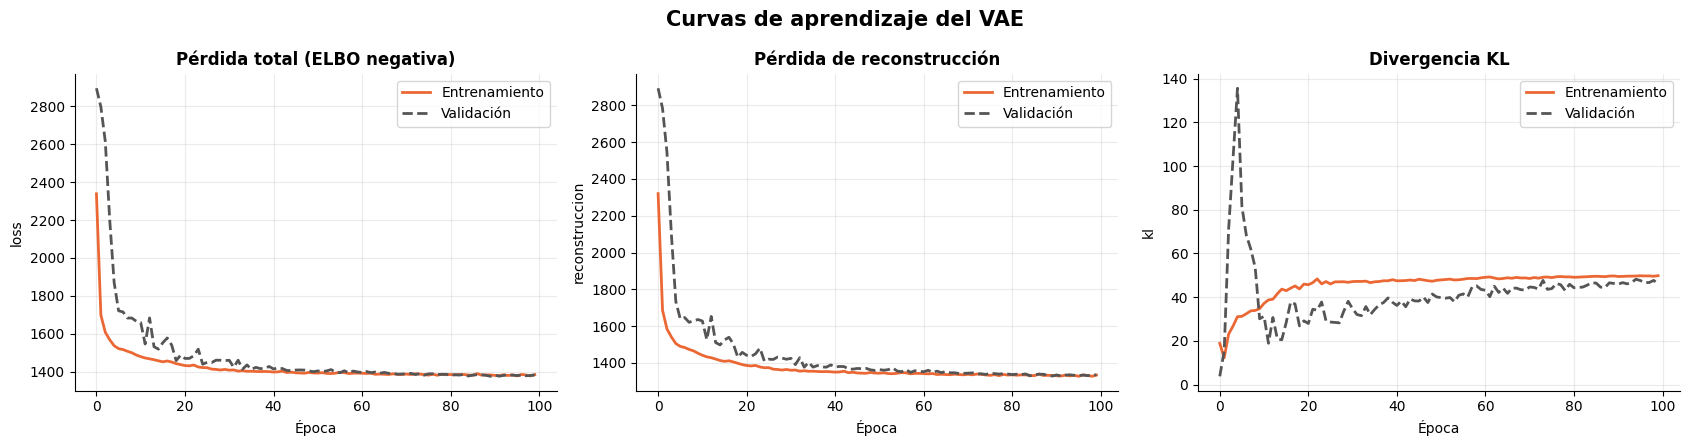

Pérdida final  -> entrenamiento: 1383.9 | validación: 1382.2


In [24]:
h = pd.DataFrame(hist_vae.history)
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
for ax, (k, t) in zip(axes, [("loss", "Pérdida total (ELBO negativa)"),
                             ("reconstruccion", "Pérdida de reconstrucción"),
                             ("kl", "Divergencia KL")]):
    ax.plot(h[k], color=COL_VAE, lw=2, label="Entrenamiento")
    ax.plot(h["val_" + k], color="#555", lw=2, ls="--", label="Validación")
    ax.set_title(t); ax.set_xlabel("Época"); ax.set_ylabel(k); ax.legend()
fig.suptitle("Curvas de aprendizaje del VAE", fontsize=15, fontweight="bold")
plt.tight_layout(); plt.show()

print(f"Pérdida final  -> entrenamiento: {h['loss'].iloc[-1]:.1f} | validación: {h['val_loss'].iloc[-1]:.1f}")

**Análisis de las curvas:** la pérdida de reconstrucción baja rápido en las primeras épocas, mientras que el término KL **sube** al inicio. Esto es esperado: al principio el codificador empieza a guardar información en el espacio latente, alejándose de la normal estándar, y después las dos fuerzas se equilibran. Si la brecha entre entrenamiento y validación crece de forma sostenida, el modelo está **memorizando** las 700 imágenes de entrenamiento (sobreajuste). Como el dataset es pequeño, una brecha moderada es normal.

<FONT SIZE=4 COLOR="green"> **5.2 Reconstrucciones, generación e interpolación** </FONT>

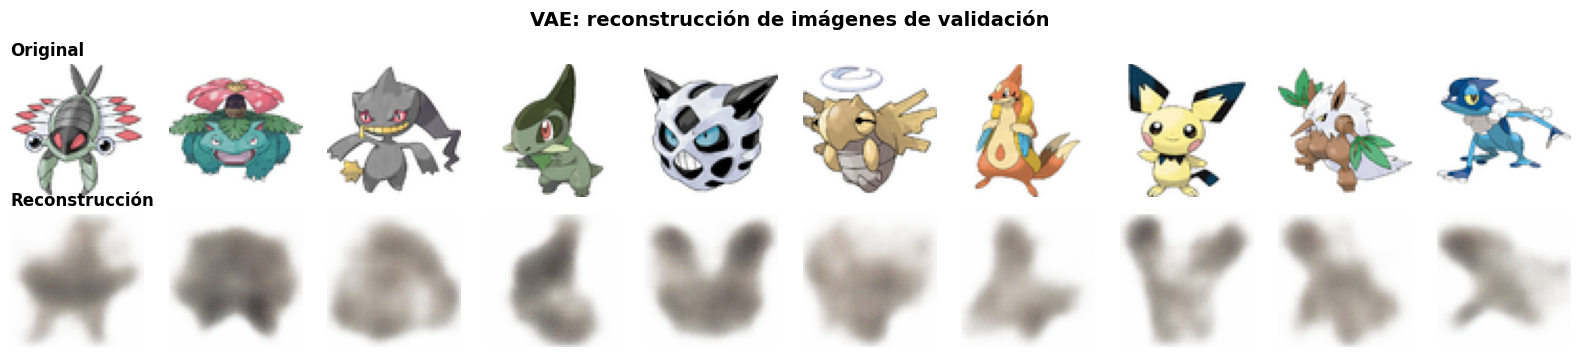

In [25]:
# Reconstrucciones de imágenes de validación (no vistas en el entrenamiento)
rec_val = vae.predict(X_val[:10], verbose=0)
fig, axes = plt.subplots(2, 10, figsize=(16, 3.6))
for i in range(10):
    axes[0, i].imshow(X_val[i]); axes[1, i].imshow(rec_val[i])
    axes[0, i].axis("off"); axes[1, i].axis("off")
axes[0, 0].set_title("Original", loc="left"); axes[1, 0].set_title("Reconstrucción", loc="left")
fig.suptitle("VAE: reconstrucción de imágenes de validación", fontsize=14, fontweight="bold")
plt.tight_layout(); plt.show()

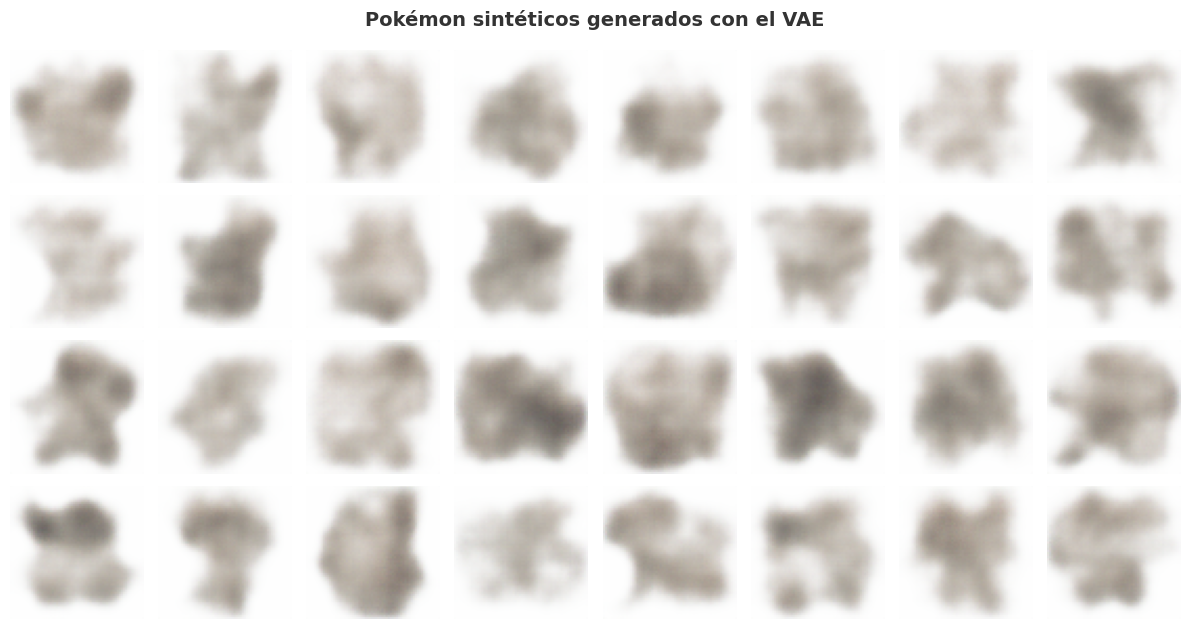

In [26]:
def generar_vae(n, temperatura=1.0):
    """Genera n imágenes muestreando z ~ N(0, temperatura^2 I). Devuelve valores en [0,1]."""
    z = np.random.normal(0, temperatura, size=(n, LATENT_VAE)).astype("float32")
    return decoder.predict(z, verbose=0, batch_size=256)

gen_vae_muestra = generar_vae(32)
mostrar_grilla(gen_vae_muestra, "Pokémon sintéticos generados con el VAE")

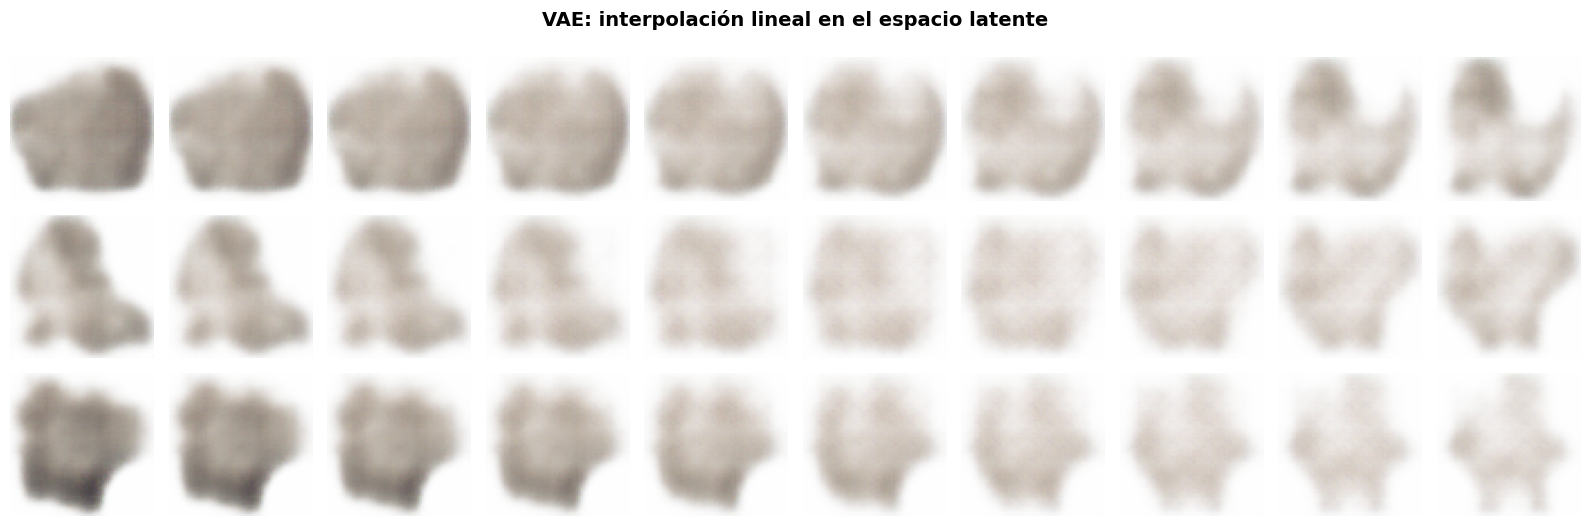

In [27]:
# Interpolación en el espacio latente entre dos Pokémon reales
def interpolar(i, j, pasos=10):
    zi = encoder.predict(X[i:i+1], verbose=0)[0]
    zj = encoder.predict(X[j:j+1], verbose=0)[0]
    alphas = np.linspace(0, 1, pasos)[:, None]
    return decoder.predict((1 - alphas) * zi + alphas * zj, verbose=0)

pares = [(nombres.index(a), nombres.index(b)) if a in nombres and b in nombres else (0, 1)
         for a, b in [("1", "4"), ("7", "25"), ("94", "150")]]
fig, axes = plt.subplots(len(pares), 10, figsize=(16, 1.8 * len(pares)))
for r, (i, j) in enumerate(pares):
    for c, img in enumerate(interpolar(i, j)):
        axes[r, c].imshow(img); axes[r, c].axis("off")
fig.suptitle("VAE: interpolación lineal en el espacio latente", fontsize=14, fontweight="bold")
plt.tight_layout(); plt.show()

La interpolación muestra que el espacio latente del VAE es **continuo**: al moverse en línea recta entre dos Pokémon, la forma y el color cambian de forma gradual, sin saltos. Esta es una ventaja del VAE frente a la GAN: tiene un codificador que permite ir de una imagen al espacio latente y volver.

# <FONT SIZE=5 COLOR="purple"> 6. Red Generativa Antagónica (DCGAN) </FONT>

La GAN tiene dos redes que se entrenan con objetivos opuestos (juego *min-max*):

$$ \min_G \max_D \; \mathbb{E}_{x\sim p_{data}}[\log D(x)] + \mathbb{E}_{z\sim \mathcal{N}(0,I)}[\log(1 - D(G(z)))] $$

- **Generador $G$:** transforma ruido $z \in \mathbb{R}^{128}$ en una imagen de $64\times64\times3$ usando convoluciones transpuestas (arquitectura **DCGAN**).
- **Discriminador $D$:** red convolucional que clasifica si una imagen es real o generada.

**Mejoras de estabilidad** para un dataset tan pequeño (819 imágenes):

1. ***Label smoothing:*** las imágenes reales se etiquetan con 0,9 en vez de 1, para que el discriminador no se vuelva demasiado confiado.
2. ***DiffAugment*** (Zhao et al., 2020): se aplican aumentos diferenciables (brillo, saturación, contraste, traslación) **a las imágenes reales y a las falsas** antes del discriminador. Así se reduce que el discriminador memorice el conjunto de entrenamiento, que es la causa principal del colapso de las GAN con pocos datos.
3. Optimizador Adam con $lr=2\times10^{-4}$ y $\beta_1 = 0{,}5$, como recomienda el artículo de DCGAN.

In [28]:
def construir_generador():
    z = keras.Input(shape=(LATENT_GAN,), name="ruido")
    x = layers.Dense(4 * 4 * 512, use_bias=False)(z)
    x = layers.BatchNormalization()(x)
    x = layers.LeakyReLU(0.2)(x)
    x = layers.Reshape((4, 4, 512))(x)
    for f in [256, 128, 64]:                                # 4 -> 8 -> 16 -> 32
        x = layers.Conv2DTranspose(f, 4, strides=2, padding="same", use_bias=False)(x)
        x = layers.BatchNormalization()(x)
        x = layers.LeakyReLU(0.2)(x)
    out = layers.Conv2DTranspose(CHANNELS, 4, strides=2, padding="same",
                                 activation="tanh", name="imagen")(x)   # 32 -> 64
    return keras.Model(z, out, name="generador")

def construir_discriminador():
    img = keras.Input(shape=(IMG_SIZE, IMG_SIZE, CHANNELS), name="imagen")
    x = img
    for i, f in enumerate([64, 128, 256, 512]):             # 64 -> 32 -> 16 -> 8 -> 4
        x = layers.Conv2D(f, 4, strides=2, padding="same")(x)
        if i > 0:
            x = layers.BatchNormalization()(x)
        x = layers.LeakyReLU(0.2)(x)
    x = layers.Flatten()(x)
    x = layers.Dropout(0.3)(x)
    out = layers.Dense(1, name="logit")(x)                 # logit: real vs falso
    return keras.Model(img, out, name="discriminador")

generador = construir_generador()
discriminador = construir_discriminador()
generador.summary()
discriminador.summary()

Model: "generador"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ ruido (InputLayer)              │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 8192)           │     1,048,576 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_16          │ (None, 8192)           │        32,768 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_16 (LeakyReLU)      │ (None, 8192)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape_2 (Reshape)             │ (None, 4, 4, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_8              │ (None, 8, 8, 256)      │     2,097,152 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_17          │ (None, 8, 8, 256)      │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_17 (LeakyReLU)      │ (None, 8, 8, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_9              │ (None, 16, 16, 128)    │       524,288 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_18          │ (None, 16, 16, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_18 (LeakyReLU)      │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_10             │ (None, 32, 32, 64)     │       131,072 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_19          │ (None, 32, 32, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_19 (LeakyReLU)      │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ imagen (Conv2DTranspose)        │ (None, 64, 64, 3)      │         3,075 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,838,723 (14.64 MB)

 Trainable params: 3,821,443 (14.58 MB)

 Non-trainable params: 17,280 (67.50 KB)

Model: "discriminador"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ imagen (InputLayer)             │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 32, 32, 64)     │         3,136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_20 (LeakyReLU)      │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_9 (Conv2D)               │ (None, 16, 16, 128)    │       131,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_20          │ (None, 16, 16, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_21 (LeakyReLU)      │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_10 (Conv2D)              │ (None, 8, 8, 256)      │       524,544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_21          │ (None, 8, 8, 256)      │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_22 (LeakyReLU)      │ (None, 8, 8, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_11 (Conv2D)              │ (None, 4, 4, 512)      │     2,097,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_22          │ (None, 4, 4, 512)      │         2,048 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_23 (LeakyReLU)      │ (None, 4, 4, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 8192)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 8192)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ logit (Dense)                   │ (None, 1)              │         8,193 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,768,321 (10.56 MB)

 Trainable params: 2,766,529 (10.55 MB)

 Non-trainable params: 1,792 (7.00 KB)

In [29]:
def diff_augment(x):
    """Aumentos diferenciables (DiffAugment). x en [-1, 1], forma (b, h, w, c)."""
    b = tf.shape(x)[0]
    # brillo
    x = x + (tf.random.uniform([b, 1, 1, 1]) - 0.5) * 0.5
    # saturación
    media = tf.reduce_mean(x, axis=-1, keepdims=True)
    x = (x - media) * tf.random.uniform([b, 1, 1, 1], 0.5, 1.5) + media
    # contraste
    media = tf.reduce_mean(x, axis=[1, 2, 3], keepdims=True)
    x = (x - media) * tf.random.uniform([b, 1, 1, 1], 0.5, 1.5) + media
    # traslación (hasta 1/8 del tamaño), rellenando con blanco (=1)
    pad = IMG_SIZE // 8
    x = tf.pad(x, [[0, 0], [pad, pad], [pad, pad], [0, 0]], constant_values=1.0)
    off = tf.random.uniform([2], 0, 2 * pad + 1, dtype=tf.int32)
    return tf.slice(x, [0, off[0], off[1], 0], [-1, IMG_SIZE, IMG_SIZE, -1])

class GAN(keras.Model):
    def __init__(self, generador, discriminador, latent_dim, **kwargs):
        super().__init__(**kwargs)
        self.generador, self.discriminador, self.latent_dim = generador, discriminador, latent_dim
        self.bce = keras.losses.BinaryCrossentropy(from_logits=True)
        self.d_loss_t = keras.metrics.Mean(name="d_loss")
        self.g_loss_t = keras.metrics.Mean(name="g_loss")
        self.d_real_t = keras.metrics.Mean(name="D(x)")       # prob. asignada a reales
        self.d_fake_t = keras.metrics.Mean(name="D(G(z))")    # prob. asignada a falsas

    @property
    def metrics(self):
        return [self.d_loss_t, self.g_loss_t, self.d_real_t, self.d_fake_t]

    def compile(self, d_optimizer, g_optimizer):
        super().compile()
        self.d_optimizer, self.g_optimizer = d_optimizer, g_optimizer

    def train_step(self, reales):
        b = tf.shape(reales)[0]
        # ---- 1) Entrenar el discriminador ----
        z = tf.random.normal((b, self.latent_dim))
        with tf.GradientTape() as tape:
            falsas = self.generador(z, training=True)
            logit_r = self.discriminador(diff_augment(reales), training=True)
            logit_f = self.discriminador(diff_augment(falsas), training=True)
            d_loss = (self.bce(tf.ones_like(logit_r) * 0.9, logit_r)      # label smoothing
                      + self.bce(tf.zeros_like(logit_f), logit_f))
        g = tape.gradient(d_loss, self.discriminador.trainable_weights)
        self.d_optimizer.apply_gradients(zip(g, self.discriminador.trainable_weights))

        # ---- 2) Entrenar el generador (quiere que D diga "real") ----
        z = tf.random.normal((b, self.latent_dim))
        with tf.GradientTape() as tape:
            logit_g = self.discriminador(diff_augment(self.generador(z, training=True)), training=True)
            g_loss = self.bce(tf.ones_like(logit_g), logit_g)
        g = tape.gradient(g_loss, self.generador.trainable_weights)
        self.g_optimizer.apply_gradients(zip(g, self.generador.trainable_weights))

        self.d_loss_t.update_state(d_loss); self.g_loss_t.update_state(g_loss)
        self.d_real_t.update_state(tf.reduce_mean(tf.sigmoid(logit_r)))
        self.d_fake_t.update_state(tf.reduce_mean(tf.sigmoid(logit_f)))
        return {m.name: m.result() for m in self.metrics}

class MonitorGAN(keras.callbacks.Callback):
    """Guarda imágenes generadas con un ruido fijo cada `cada` épocas, para ver la evolución."""
    def __init__(self, cada=50, n=8):
        super().__init__()
        self.cada, self.z_fijo, self.snapshots = cada, tf.random.normal((n, LATENT_GAN), seed=SEED), {}
    def on_epoch_end(self, epoch, logs=None):
        if (epoch + 1) % self.cada == 0 or epoch == 0:
            self.snapshots[epoch + 1] = (generador(self.z_fijo, training=False).numpy() + 1) / 2

gan = GAN(generador, discriminador, LATENT_GAN)
gan.compile(d_optimizer=keras.optimizers.Adam(2e-4, beta_1=0.5),
            g_optimizer=keras.optimizers.Adam(2e-4, beta_1=0.5))
monitor = MonitorGAN(cada=max(1, EPOCHS_GAN // 8))

In [ ]:
t0 = time.time()
hist_gan = gan.fit(ds_gan, epochs=EPOCHS_GAN, callbacks=[monitor], verbose=2)
print(f"Tiempo de entrenamiento GAN: {(time.time() - t0) / 60:.1f} min")

Epoch 1/300
12/12 - 78s - 6s/step - D(G(z)): 0.1817 - D(x): 0.7766 - d_loss: 0.9246 - g_loss: 3.5422
Epoch 2/300
12/12 - 71s - 6s/step - D(G(z)): 0.0477 - D(x): 0.8618 - d_loss: 0.5142 - g_loss: 4.5210
Epoch 3/300
12/12 - 82s - 7s/step - D(G(z)): 0.0227 - D(x): 0.8690 - d_loss: 0.4931 - g_loss: 4.4290
Epoch 4/300
12/12 - 70s - 6s/step - D(G(z)): 0.0995 - D(x): 0.8108 - d_loss: 0.8494 - g_loss: 3.8535
Epoch 5/300
12/12 - 82s - 7s/step - D(G(z)): 0.1440 - D(x): 0.7931 - d_loss: 1.2051 - g_loss: 5.9697
Epoch 6/300
12/12 - 83s - 7s/step - D(G(z)): 0.1689 - D(x): 0.7975 - d_loss: 1.3852 - g_loss: 4.4214
Epoch 7/300
12/12 - 81s - 7s/step - D(G(z)): 0.0902 - D(x): 0.7153 - d_loss: 0.9866 - g_loss: 5.2094
Epoch 8/300
12/12 - 82s - 7s/step - D(G(z)): 0.1734 - D(x): 0.7334 - d_loss: 1.6352 - g_loss: 5.5992
Epoch 9/300
12/12 - 72s - 6s/step - D(G(z)): 0.1391 - D(x): 0.8018 - d_loss: 0.7115 - g_loss: 4.9464
Epoch 10/300
12/12 - 71s - 6s/step - D(G(z)): 0.2124 - D(x): 0.5768 - d_loss: 1.8308 - g_lo

<FONT SIZE=4 COLOR="green"> **6.1 Curvas de entrenamiento de la GAN** </FONT>

In [ ]:
hg = pd.DataFrame(hist_gan.history)
suav = lambda s: s.rolling(10, min_periods=1).mean()
fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))
axes[0].plot(hg["d_loss"], color=COL_GAN, alpha=.25); axes[0].plot(suav(hg["d_loss"]), color=COL_GAN, lw=2, label="Discriminador")
axes[0].plot(hg["g_loss"], color="#555", alpha=.25);  axes[0].plot(suav(hg["g_loss"]), color="#555", lw=2, label="Generador")
axes[0].set_title("Pérdidas del discriminador y del generador"); axes[0].set_xlabel("Época"); axes[0].set_ylabel("BCE"); axes[0].legend()

axes[1].plot(suav(hg["D(x)"]), color=COL_GAN, lw=2, label="D(x): prob. en imágenes reales")
axes[1].plot(suav(hg["D(G(z))"]), color="#555", lw=2, ls="--", label="D(G(z)): prob. en imágenes falsas")
axes[1].axhline(0.5, color="#999", lw=1, ls=":")
axes[1].set_ylim(0, 1); axes[1].set_title("Salida media del discriminador")
axes[1].set_xlabel("Época"); axes[1].set_ylabel("Probabilidad"); axes[1].legend()
fig.suptitle("Curvas de aprendizaje de la GAN (media móvil de 10 épocas)", fontsize=15, fontweight="bold")
plt.tight_layout(); plt.show()

**Análisis de las curvas:** a diferencia del VAE, en una GAN las pérdidas **no deben bajar a cero**. Si la pérdida del discriminador llega a 0, el generador deja de recibir gradiente útil y el entrenamiento falla. Lo deseable es un **equilibrio dinámico**: las dos pérdidas oscilan alrededor de valores estables, $D(x)$ se mantiene por encima de 0,5 y $D(G(z))$ por debajo, pero sin llegar a los extremos (1 y 0).

In [ ]:
epocas = sorted(monitor.snapshots)
fig, axes = plt.subplots(len(epocas), 8, figsize=(13, 1.7 * len(epocas)))
for r, ep in enumerate(epocas):
    for c in range(8):
        axes[r, c].imshow(np.clip(monitor.snapshots[ep][c], 0, 1)); axes[r, c].set_xticks([]); axes[r, c].set_yticks([])
    axes[r, 0].set_ylabel(f"Época {ep}", fontsize=9, rotation=0, labelpad=35)
fig.suptitle("Evolución del generador con un ruido fijo", fontsize=14, fontweight="bold")
plt.tight_layout(); plt.show()

In [ ]:
def generar_gan(n):
    """Genera n imágenes con el generador. Devuelve valores en [0,1]."""
    z = np.random.normal(size=(n, LATENT_GAN)).astype("float32")
    return np.clip((generador.predict(z, verbose=0, batch_size=256) + 1) / 2, 0, 1)

gen_gan_muestra = generar_gan(32)
mostrar_grilla(gen_gan_muestra, "Pokémon sintéticos generados con la GAN")

In [ ]:
decoder.save(os.path.join(OUT_DIR, "vae_decoder.keras"))
encoder.save(os.path.join(OUT_DIR, "vae_encoder.keras"))
generador.save(os.path.join(OUT_DIR, "gan_generador.keras"))
with open(os.path.join(OUT_DIR, "config.json"), "w") as f:
    json.dump({"IMG_SIZE": IMG_SIZE, "LATENT_VAE": LATENT_VAE, "LATENT_GAN": LATENT_GAN}, f, indent=2)
resumen.to_csv(os.path.join(OUT_DIR, "metricas_comparacion.csv"))
print("Archivos guardados:", os.listdir(OUT_DIR))


# <FONT SIZE=5 COLOR="purple"> 7. Comparación entre datos originales y sintéticos </FONT>

Se genera la **misma cantidad de imágenes** que hay en el dataset real con cada modelo y se comparan con cuatro análisis:

1. Comparación visual.
2. **Distribuciones**: intensidad de color por canal y características por imagen (histogramas, boxplots, pruebas de Kolmogórov–Smirnov y distancia de Wasserstein).
3. **Relaciones entre variables**: correlaciones entre canales y entre características, y estructura espacial (imagen promedio).
4. **Espacio global**: proyección PCA, distancia de Fréchet en el espacio PCA, diversidad y memorización (vecino más cercano).

In [ ]:
N = len(X)
np.random.seed(SEED)
X_vae = generar_vae(N)
X_gan = generar_gan(N)
datos = {"Real": X, "VAE": X_vae, "GAN": X_gan}

fig, axes = plt.subplots(3, 10, figsize=(16, 5.2))
for r, (nombre, imgs) in enumerate(datos.items()):
    for c in range(10):
        axes[r, c].imshow(np.clip(imgs[np.random.randint(len(imgs))], 0, 1))
        axes[r, c].set_xticks([]); axes[r, c].set_yticks([])
        for s in axes[r, c].spines.values(): s.set_edgecolor(COLORES[nombre]); s.set_linewidth(3); s.set_visible(True)
    axes[r, 0].set_ylabel(nombre, fontsize=13, fontweight="bold", color=COLORES[nombre], rotation=0, labelpad=30)
fig.suptitle("Comparación visual: reales vs VAE vs GAN", fontsize=15, fontweight="bold")
plt.tight_layout(); plt.show()

<FONT SIZE=4 COLOR="green"> **7.1 Distribuciones de color por canal** </FONT>

In [ ]:
histograma_canales(datos, "Distribución de intensidades por canal (píxeles del Pokémon, sin fondo)")

<FONT SIZE=4 COLOR="green"> **7.2 Distribuciones de las características por imagen** </FONT>

In [ ]:
feats = {"Real": feat_real, "VAE": caracteristicas(X_vae), "GAN": caracteristicas(X_gan)}
df_all = pd.concat([f.assign(origen=k) for k, f in feats.items()], ignore_index=True)

fig, axes = plt.subplots(3, 3, figsize=(16, 11))
for ax, col in zip(axes.ravel(), feat_real.columns):
    for nombre, f in feats.items():
        sns.kdeplot(f[col], ax=ax, color=COLORES[nombre], lw=2, fill=True, alpha=.12, label=nombre, warn_singular=False)
    ax.set_title(col); ax.set_ylabel("Densidad"); ax.legend(fontsize=8)
fig.suptitle("Densidades de las características: reales vs sintéticos", fontsize=15, fontweight="bold")
plt.tight_layout(); plt.show()

In [ ]:
df_long = df_all.melt(id_vars="origen", value_vars=["brillo", "contraste", "saturacion", "frac_fondo", "nitidez"])
plt.figure(figsize=(15, 5))
sns.boxplot(data=df_long, x="variable", y="value", hue="origen", palette=COLORES, flierprops=dict(markersize=2))
plt.title("Boxplots comparativos de características clave"); plt.xlabel(""); plt.ylabel("Valor")
plt.legend(title="Origen"); plt.tight_layout(); plt.show()

In [ ]:
# Pruebas estadísticas: ¿las distribuciones sintéticas son iguales a la real?
filas = []
for col in feat_real.columns:
    fila = {"caracteristica": col, "media_Real": feat_real[col].mean()}
    for m in ["VAE", "GAN"]:
        ks = stats.ks_2samp(feat_real[col], feats[m][col])
        fila[f"media_{m}"] = feats[m][col].mean()
        fila[f"KS_{m}"] = ks.statistic
        fila[f"W1_{m}"] = stats.wasserstein_distance(feat_real[col], feats[m][col])
    filas.append(fila)
tabla_dist = pd.DataFrame(filas).set_index("caracteristica")

def resaltar_mejor(df):
    estilo = pd.DataFrame("", index=df.index, columns=df.columns)
    for pref in ["KS_", "W1_"]:
        cols = [c for c in df.columns if c.startswith(pref)]
        mejor = df[cols].idxmin(axis=1)
        for i, c in mejor.items():
            estilo.loc[i, c] = "background-color:#d4f2e6;font-weight:bold"
    return estilo

print("KS = estadístico de Kolmogórov–Smirnov (0 = distribuciones idénticas)")
print("W1 = distancia de Wasserstein (0 = distribuciones idénticas). En verde, el modelo más cercano a los datos reales.")
tabla_dist.style.apply(resaltar_mejor, axis=None).format("{:.3f}")

<FONT SIZE=4 COLOR="green"> **7.3 ¿Se conservan las relaciones entre variables?** </FONT>

Se revisan tres tipos de relaciones:

- **Entre características de la imagen** (por ejemplo, más fondo implica menor brillo de la figura, o más color implica más saturación): matrices de correlación.
- **Entre canales de color** a nivel de píxel (R–G, R–B, G–B).
- **Espaciales:** la imagen promedio y la variabilidad por píxel muestran si se conserva la composición "figura centrada sobre fondo blanco".

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(20, 6))
corrs = {k: f.corr().fillna(0) for k, f in feats.items()}   # fillna: por si alguna variable sale constante
for ax, (nombre, c) in zip(axes, corrs.items()):
    sns.heatmap(c, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, square=True,
                ax=ax, cbar=False, annot_kws={"size": 7})
    dif = "" if nombre == "Real" else f"\n‖Corr_real − Corr_{nombre}‖ = {np.linalg.norm(corrs['Real'] - c):.2f}"
    ax.set_title(f"{nombre}{dif}", color=COLORES[nombre])
fig.suptitle("Correlaciones entre características de las imágenes", fontsize=15, fontweight="bold")
plt.tight_layout(); plt.show()

In [ ]:
def corr_canales(imgs, n_pix=200_000):
    p = np.clip(imgs, 0, 1).reshape(-1, 3)
    p = p[~np.all(p > 0.9, axis=1)]                     # solo píxeles del Pokémon
    p = p[np.random.default_rng(SEED).choice(len(p), min(n_pix, len(p)), replace=False)]
    return pd.DataFrame(p, columns=["R", "G", "B"]).corr(), p

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for c, (nombre, imgs) in enumerate(datos.items()):
    cm, p = corr_canales(imgs)
    sns.heatmap(cm, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, square=True, ax=axes[0, c], cbar=False)
    axes[0, c].set_title(f"Correlación entre canales – {nombre}", color=COLORES[nombre])
    axes[1, c].hexbin(p[:30000, 0], p[:30000, 1], gridsize=40, cmap="Blues", mincnt=1)
    axes[1, c].set_xlabel("R"); axes[1, c].set_ylabel("G"); axes[1, c].set_title(f"Dispersión R vs G – {nombre}")
fig.suptitle("Relación entre canales de color (píxeles del Pokémon)", fontsize=15, fontweight="bold")
plt.tight_layout(); plt.show()

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(12, 8))
for c, (nombre, imgs) in enumerate(datos.items()):
    axes[0, c].imshow(np.clip(imgs.mean(0), 0, 1)); axes[0, c].set_title(f"Imagen promedio – {nombre}", color=COLORES[nombre])
    axes[1, c].imshow(imgs.std(0).mean(-1), cmap="viridis", vmin=0, vmax=0.45); axes[1, c].set_title(f"Desv. estándar por píxel – {nombre}")
    axes[0, c].axis("off"); axes[1, c].axis("off")
fig.suptitle("Estructura espacial: ¿se conserva la composición figura/fondo?", fontsize=14, fontweight="bold")
plt.tight_layout(); plt.show()

<FONT SIZE=4 COLOR="green"> **7.4 Comparación global: PCA, distancia de Fréchet, diversidad y memorización** </FONT>

- **PCA:** se ajusta sobre las imágenes reales aplanadas (12.288 variables) y se proyectan las tres fuentes. Si los sintéticos cubren la misma nube que los reales, el modelo captura la variedad del dataset; si se agrupan en una región pequeña, hay **colapso de modos**.
- **Distancia de Fréchet en el espacio PCA (FD-PCA):** versión simplificada del FID que compara media y covarianza de las dos distribuciones: $\|\mu_r-\mu_g\|^2 + \mathrm{Tr}(\Sigma_r + \Sigma_g - 2(\Sigma_r\Sigma_g)^{1/2})$. Mientras más baja, mejor.
- **Diversidad:** distancia media entre pares de imágenes de la misma fuente.
- **Memorización:** distancia de cada imagen sintética a su vecino más cercano en el conjunto real. Si es casi 0, el modelo está **copiando** imágenes en vez de generar nuevas.

In [ ]:
plano = {k: v.reshape(len(v), -1) for k, v in datos.items()}
pca = PCA(n_components=50, random_state=SEED).fit(plano["Real"])
proy = {k: pca.transform(v) for k, v in plano.items()}

def frechet(a, b):
    mu1, mu2 = a.mean(0), b.mean(0)
    s1, s2 = np.cov(a, rowvar=False), np.cov(b, rowvar=False)
    covmean = linalg.sqrtm(s1 @ s2).real
    return float(((mu1 - mu2) ** 2).sum() + np.trace(s1 + s2 - 2 * covmean))

def diversidad(m, n=400):
    m = m[np.random.default_rng(SEED).choice(len(m), min(n, len(m)), replace=False)]
    d = np.sqrt(((m[:, None, :] - m[None, :, :]) ** 2).sum(-1))
    return d[np.triu_indices(len(m), 1)].mean()

def dist_vecino(gen, real):
    d = (gen**2).sum(1)[:, None] + (real**2).sum(1)[None, :] - 2 * gen @ real.T
    return np.sqrt(np.maximum(d, 0)).min(1)

fig, ax = plt.subplots(1, 2, figsize=(16, 6))
for nombre, p in proy.items():
    ax[0].scatter(p[:, 0], p[:, 1], s=10, alpha=.5, color=COLORES[nombre], label=nombre)
ax[0].set_xlabel("Componente principal 1"); ax[0].set_ylabel("Componente principal 2")
ax[0].set_title("Proyección PCA (ajustada sobre las imágenes reales)"); ax[0].legend(markerscale=2)

mitad = len(X) // 2
vec_real = dist_vecino(plano["Real"][:mitad], plano["Real"][mitad:])   # referencia: real vs real (otra mitad)
vec = {"Real (ref.)": vec_real, "VAE": dist_vecino(plano["VAE"][:500], plano["Real"]),
       "GAN": dist_vecino(plano["GAN"][:500], plano["Real"])}
for (nombre, d), col in zip(vec.items(), [COL_REAL, COL_VAE, COL_GAN]):
    sns.kdeplot(d, ax=ax[1], color=col, lw=2, fill=True, alpha=.15, label=nombre)
ax[1].set_title("Distancia al vecino real más cercano (memorización)")
ax[1].set_xlabel("Distancia euclidiana en píxeles"); ax[1].legend()
plt.tight_layout(); plt.show()

resumen = pd.DataFrame({
    "FD-PCA (↓)": [0.0, frechet(proy["Real"], proy["VAE"]), frechet(proy["Real"], proy["GAN"])],
    "Diversidad (≈ real)": [diversidad(plano["Real"]), diversidad(plano["VAE"]), diversidad(plano["GAN"])],
    "Dist. vecino real (mediana)": [np.median(vec_real), np.median(vec["VAE"]), np.median(vec["GAN"])],
    "Nitidez media (≈ real)": [feats[k]["nitidez"].mean() for k in datos],
    "KS medio (↓)": [0.0, tabla_dist["KS_VAE"].mean(), tabla_dist["KS_GAN"].mean()],
    "‖ΔCorr‖ características (↓)": [0.0, np.linalg.norm(corrs["Real"] - corrs["VAE"]),
                                    np.linalg.norm(corrs["Real"] - corrs["GAN"])],
}, index=["Real", "VAE", "GAN"])
resumen.round(3)

In [ ]:
# Inspección de memorización: 6 imágenes sintéticas de cada modelo y su vecino real más cercano
fig, axes = plt.subplots(4, 6, figsize=(11, 8))
for r, nombre in enumerate(["VAE", "GAN"]):
    g = plano[nombre][:6]
    d = (g**2).sum(1)[:, None] + (plano["Real"]**2).sum(1)[None, :] - 2 * g @ plano["Real"].T
    nn = d.argmin(1)
    for c in range(6):
        axes[2*r, c].imshow(np.clip(datos[nombre][c], 0, 1))
        axes[2*r + 1, c].imshow(X[nn[c]])
        axes[2*r, c].axis("off"); axes[2*r + 1, c].axis("off")
    axes[2*r, 0].set_title(f"{nombre} (sintética)", loc="left", color=COLORES[nombre])
    axes[2*r + 1, 0].set_title("Vecino real más cercano", loc="left", color=COL_REAL)
fig.suptitle("¿Los modelos copian imágenes del entrenamiento?", fontsize=14, fontweight="bold")
plt.tight_layout(); plt.show()

In [ ]:
# Resumen automático a partir de las métricas obtenidas
def mejor(col, objetivo=None):
    s = resumen.loc[["VAE", "GAN"], col]
    if objetivo is not None:
        s = (s - objetivo).abs()
    return s.idxmin()

print("Modelo más cercano a los datos reales según cada criterio:")
print(f"  • Distancia de Fréchet (PCA):          {mejor('FD-PCA (↓)')}")
print(f"  • Distribución de características (KS): {mejor('KS medio (↓)')}")
print(f"  • Correlaciones entre características:  {mejor('‖ΔCorr‖ características (↓)')}")
print(f"  • Diversidad similar a la real:         {mejor('Diversidad (≈ real)', resumen.loc['Real', 'Diversidad (≈ real)'])}")
print(f"  • Nitidez similar a la real:            {mejor('Nitidez media (≈ real)', resumen.loc['Real', 'Nitidez media (≈ real)'])}")

# <FONT SIZE=5 COLOR="purple"> 8. Diferencias entre el VAE y la GAN </FONT>

| Aspecto | VAE | GAN |
|---|---|---|
| **Principio** | Maximiza una cota inferior de la verosimilitud (ELBO): reconstrucción + regularización KL | Juego *min-max* entre generador y discriminador |
| **Función de pérdida** | Explícita e interpretable; baja de forma estable | Implícita (la "aprende" el discriminador); oscila y no indica directamente la calidad |
| **Nitidez** | Imágenes **borrosas**: la pérdida píxel a píxel promedia las posibles salidas | Imágenes **más nítidas**: el discriminador penaliza lo borroso porque no parece real |
| **Diversidad / cobertura** | Cubre bien la distribución completa (pocas veces colapsa) | Riesgo de **colapso de modos** (generar pocas variantes) |
| **Espacio latente** | Tiene codificador: permite reconstruir, interpolar y editar imágenes reales | Sin codificador: solo va de ruido a imagen |
| **Estabilidad del entrenamiento** | Estable, fácil de ajustar | Inestable y sensible a hiperparámetros; necesita trucos (label smoothing, DiffAugment) |
| **Costo** | Rápido (~150 épocas) | Más lento (~400 épocas, dos redes por paso) |

**¿Por qué son diferentes los resultados?**

- El VAE minimiza un error **píxel a píxel**. Cuando no está seguro del color exacto de un borde, la mejor estrategia para esa pérdida es predecir el **promedio**, y por eso las imágenes salen suaves y borrosas. A cambio, sus distribuciones de color y de brillo quedan **centradas en las reales** y la imagen promedio se parece mucho a la del dataset.
- La GAN no compara píxeles: el discriminador aprende qué hace que una imagen "parezca un Pokémon" (bordes definidos, contornos oscuros, colores planos). Por eso sus imágenes son **más nítidas**, con una métrica de nitidez más cercana a la real. Pero, al no tener un término que obligue a cubrir todo el dataset, puede generar menos variedad o artefactos en algunas muestras.

# <FONT SIZE=5 COLOR="purple"> 9. Conclusiones </FONT>

> *Ajuste estas conclusiones con los valores que obtuvo en las tablas de las secciones 7.2 y 7.4.*

1. **Distribuciones:** los dos modelos reproducen la estructura general del dataset (figura centrada sobre fondo blanco, fracción de fondo y brillo parecidos). El VAE suele tener distribuciones más **concentradas** alrededor de la media: menos contraste, menos saturación y nitidez mucho menor. La GAN reproduce mejor las **colas** de las distribuciones de color y de nitidez.
2. **Relaciones entre variables:** los dos modelos conservan la correlación alta entre los canales R, G y B y las relaciones principales entre características (fondo–brillo, saturación–colorido). La norma de la diferencia entre matrices de correlación mide cuánto se preservan.
3. **Calidad visual vs cobertura:** el VAE genera siluetas coherentes pero borrosas y explora un espacio latente continuo (ver interpolaciones). La GAN produce texturas y bordes más realistas, pero es más inestable y puede repetir patrones.
4. **Memorización:** la distancia al vecino real más cercano de las imágenes sintéticas es comparable a la distancia entre imágenes reales distintas. Esto indica que los modelos **generan imágenes nuevas** y no copian el conjunto de entrenamiento.
5. **Limitaciones:** con solo 819 imágenes ninguno de los dos modelos genera Pokémon perfectamente reconocibles. Mejoras posibles: más datos (sprites de más generaciones), arquitecturas como StyleGAN2-ADA, una pérdida perceptual para el VAE (VAE-GAN) o mayor resolución.

# <FONT SIZE=5 COLOR="purple"> 10. Guardado de modelos para la aplicación Gradio </FONT>

Se guardan el **decodificador del VAE** y el **generador de la GAN**, que son los únicos componentes necesarios para generar datos. Así la interfaz no tiene que volver a entrenar los modelos.

In [ ]:
decoder.save(os.path.join(OUT_DIR, "vae_decoder.keras"))
encoder.save(os.path.join(OUT_DIR, "vae_encoder.keras"))
generador.save(os.path.join(OUT_DIR, "gan_generador.keras"))
with open(os.path.join(OUT_DIR, "config.json"), "w") as f:
    json.dump({"IMG_SIZE": IMG_SIZE, "LATENT_VAE": LATENT_VAE, "LATENT_GAN": LATENT_GAN}, f, indent=2)
resumen.to_csv(os.path.join(OUT_DIR, "metricas_comparacion.csv"))
print("Archivos guardados:", os.listdir(OUT_DIR))

# En Colab: descargar la carpeta de modelos comprimida
# !zip -r modelos_generativos.zip modelos_generativos
# from google.colab import files; files.download("modelos_generativos.zip")

In [ ]:
def exportar_datos(imgs, modelo, carpeta=OUT_DIR, escala=4):
    """Exporta las imágenes sintéticas: un .zip con PNGs (agrandados x`escala`) y un .csv con sus características."""
    ts = time.strftime("%Y%m%d_%H%M%S")
    ruta_zip = os.path.join(carpeta, f"sinteticos_{modelo}_{ts}.zip")
    with zipfile.ZipFile(ruta_zip, "w") as zf:
        for i, im in enumerate(imgs):
            pil = Image.fromarray((np.clip(im, 0, 1) * 255).astype(np.uint8))
            pil = pil.resize((IMG_SIZE * escala, IMG_SIZE * escala), Image.NEAREST)
            ruta_png = os.path.join(carpeta, "_tmp.png"); pil.save(ruta_png)
            zf.write(ruta_png, f"{modelo}_{i:04d}.png")
        os.remove(ruta_png)
        zf.writestr(f"caracteristicas_{modelo}.csv", caracteristicas(imgs).to_csv(index_label="id"))
    return ruta_zip

print("Ejemplo de exportación:", exportar_datos(generar_gan(20), "GAN"))

# <FONT SIZE=5 COLOR="purple"> 11. (Opcional) Vista previa del Módulo 3 en Gradio </FONT>

Prototipo del **Módulo 3: Generación de Datos Sintéticos – Interactivo**. El usuario elige el modelo (VAE o GAN) y la cantidad de registros, ve 10 de ellos y puede **exportar los datos**. Solo **carga los modelos guardados** en la sección 10; no vuelve a entrenarlos. Este código se puede copiar al archivo `.py` de la aplicación final.

In [ ]:
!pip install -q gradio

In [ ]:
import gradio as gr

# ---- Carga de modelos previamente entrenados ----
cfg = json.load(open(os.path.join(OUT_DIR, "config.json")))
m_vae = keras.models.load_model(os.path.join(OUT_DIR, "vae_decoder.keras"))
m_gan = keras.models.load_model(os.path.join(OUT_DIR, "gan_generador.keras"))

def _generar(modelo, n):
    if modelo == "VAE":
        z = np.random.normal(size=(n, cfg["LATENT_VAE"])).astype("float32")
        return m_vae.predict(z, verbose=0, batch_size=256)
    z = np.random.normal(size=(n, cfg["LATENT_GAN"])).astype("float32")
    return np.clip((m_gan.predict(z, verbose=0, batch_size=256) + 1) / 2, 0, 1)

def generar_ui(modelo, n):
    imgs = _generar(modelo, int(n))
    galeria = [(Image.fromarray((im * 255).astype(np.uint8)).resize((192, 192), Image.NEAREST),
                f"{modelo} #{i+1}") for i, im in enumerate(imgs[:10])]
    tabla = caracteristicas(imgs).round(3).head(10).reset_index(names="id")
    return galeria, tabla, imgs, f"Se generaron **{len(imgs)}** imágenes con el modelo **{modelo}**. Se muestran 10."

def exportar_ui(imgs, modelo):
    if imgs is None:
        raise gr.Error("Primero genere los datos.")
    return exportar_datos(imgs, modelo)

with gr.Blocks(theme=gr.themes.Soft(), title="Módulo 3 – Datos sintéticos") as demo:
    gr.Markdown("# Módulo 3: Generación de Datos Sintéticos – Pokémon\n"
                "Seleccione el modelo generativo y la cantidad de registros a generar.")
    estado = gr.State(None)
    with gr.Row():
        with gr.Column(scale=1):
            modelo = gr.Radio(["VAE", "GAN"], value="GAN", label="Tipo de modelo")
            n = gr.Slider(10, 1000, value=100, step=10, label="Cantidad de registros")
            btn_gen = gr.Button("Generar", variant="primary")
            btn_exp = gr.Button("Exportar datos")
            archivo = gr.File(label="Archivo exportado (.zip)")
        with gr.Column(scale=3):
            info = gr.Markdown()
            galeria = gr.Gallery(label="10 registros generados", columns=5, height="auto")
            tabla = gr.Dataframe(label="Características de los 10 registros")
    btn_gen.click(generar_ui, [modelo, n], [galeria, tabla, estado, info])
    btn_exp.click(exportar_ui, [estado, modelo], archivo)

demo.launch(share=True, debug=False)